In [3]:
# 1. Install dependencies (Google Colab / Kaggle)
!pip -q install timm albumentations opencv-python-headless scikit-learn pandas matplotlib seaborn

import os, random, json, math, copy, warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import CosineAnnealingLR

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: CPU training for this hybrid architecture will be very slow.")


PyTorch: 2.11.0+cu128
timm: 1.0.29
Device: cuda
GPU: Tesla T4


In [4]:
# 2. Configuration — edit DATA_ROOT if automatic discovery does not find HAM10000
class Config:
    # Expected root contains HAM10000_metadata.csv and one or both image folders:
    # HAM10000_images_part_1/ and HAM10000_images_part_2/
    DATA_ROOT = None  # Example: "/kaggle/input/skin-cancer-mnist-ham10000"

    # HAM10000 canonical seven-class order; this mapping is used everywhere.
    CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
    CLASS_FULL = {
        "akiec": "Actinic keratoses / intraepithelial carcinoma",
        "bcc": "Basal cell carcinoma",
        "bkl": "Benign keratosis-like lesions",
        "df": "Dermatofibroma",
        "mel": "Melanoma",
        "nv": "Melanocytic nevi",
        "vasc": "Vascular lesions",
    }
    NUM_CLASSES = len(CLASS_NAMES)

    # Metadata one-hot categories. Unseen/missing values map to "unknown".
    SITES = [
        "abdomen", "back", "chest", "ear", "face", "foot", "genital",
        "hand", "lower extremity", "neck", "scalp", "trunk",
        "upper extremity", "acral", "oral/genital", "unknown"
    ]
    AGE_SCALE = 90.0
    META_DIM = 2 + 3 + len(SITES)  # normalized age + age-missing + sex(3) + site one-hot

    # Hybrid models are memory-heavy. Start with a smoke test (2-3 epochs).
    IMG_SIZE = 384  # matches the selected Swin V2 pretrained checkpoint
    BATCH_SIZE = 2
    GRAD_ACCUM_STEPS = 4
    NUM_WORKERS = 2
    EPOCHS = 10
    PRETRAINED = True
    USE_AMP = torch.cuda.is_available()
    LR_BACKBONES = 1e-5
    LR_HEADS = 1e-4
    WEIGHT_DECAY = 1e-4
    LABEL_SMOOTHING = 0.05
    SEED = 42
    OUTPUT_DIR = Path("./skinlens_ham10000_output")

Config.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=Config.SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print("Classes:", Config.CLASS_NAMES)
print("Metadata vector size:", Config.META_DIM)


Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Metadata vector size: 21


In [5]:
# 3. Dataset discovery, image indexing, and leakage-safe train/val/test split
def discover_data_root():
    if Config.DATA_ROOT:
        root = Path(Config.DATA_ROOT).expanduser()
        if not root.exists():
            raise FileNotFoundError(f"Config.DATA_ROOT does not exist: {root}")
        return root

    candidates = [
        Path("/kaggle/input/skin-cancer-mnist-ham10000"),
        Path("/kaggle/input"),
        Path("/content/drive/MyDrive"),
        Path("/content"),
        Path("."),
    ]
    for base in candidates:
        if base.exists():
            found = list(base.rglob("HAM10000_metadata.csv"))
            if found:
                return found[0].parent
    raise FileNotFoundError(
        "Could not find HAM10000_metadata.csv. Set Config.DATA_ROOT to the folder containing it."
    )

DATA_ROOT = discover_data_root()
metadata_candidates = list(DATA_ROOT.rglob("HAM10000_metadata.csv"))
if not metadata_candidates:
    raise FileNotFoundError(f"No HAM10000_metadata.csv found below {DATA_ROOT}")
metadata_path = metadata_candidates[0]
print("Data root:", DATA_ROOT)
print("Metadata:", metadata_path)

df = pd.read_csv(metadata_path)
required_cols = {"image_id", "lesion_id", "dx"}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"Metadata is missing required columns: {missing_cols}")

# Build image_id -> full path index across both HAM10000 image folders.
image_index = {}
for ext in ("*.jpg", "*.jpeg", "*.png"):
    for fp in DATA_ROOT.rglob(ext):
        image_index[fp.stem] = str(fp.resolve())

df["image_path"] = df["image_id"].astype(str).map(image_index)
df = df.dropna(subset=["image_path"]).copy()
df["dx"] = df["dx"].astype(str).str.lower().str.strip()
df = df[df["dx"].isin(Config.CLASS_NAMES)].copy()
df["class_encoded"] = df["dx"].map({name: i for i, name in enumerate(Config.CLASS_NAMES)}).astype(int)
df["lesion_id"] = df["lesion_id"].fillna(df["image_id"]).astype(str)

if "age" not in df.columns: df["age"] = np.nan
if "sex" not in df.columns: df["sex"] = "unknown"
if "localization" not in df.columns: df["localization"] = "unknown"
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["sex"] = df["sex"].fillna("unknown").astype(str).str.lower().str.strip()
df["localization"] = df["localization"].fillna("unknown").astype(str).str.lower().str.strip()
df.loc[~df["sex"].isin(["female", "male"]), "sex"] = "unknown"
df.loc[~df["localization"].isin(Config.SITES), "localization"] = "unknown"

print(f"Images matched: {len(df):,}")
print("Unique lesions:", df["lesion_id"].nunique())
print("\nClass counts:")
print(df["dx"].value_counts().reindex(Config.CLASS_NAMES, fill_value=0))

# 5-fold StratifiedGroupKFold: one fold test, then one fold validation from remaining data.
# This approximates 60/20/20 while keeping lesion IDs separate.
sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=Config.SEED)
trainval_idx, test_idx = next(sgkf_test.split(df, y=df["class_encoded"], groups=df["lesion_id"]))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

sgkf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=Config.SEED + 1)
train_idx, val_idx = next(sgkf_val.split(
    trainval_df, y=trainval_df["class_encoded"], groups=trainval_df["lesion_id"]
))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

# Assert no lesion leakage between splits.
train_groups, val_groups, test_groups = set(train_df.lesion_id), set(val_df.lesion_id), set(test_df.lesion_id)
assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

for split_name, split_df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{split_name}: {len(split_df):,} images | {split_df.lesion_id.nunique():,} lesions")
    print(split_df["dx"].value_counts().reindex(Config.CLASS_NAMES, fill_value=0).to_dict())

# Save exact manifests for reproducibility.
for name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    split_df.to_csv(Config.OUTPUT_DIR / f"{name}_manifest.csv", index=False)
print("Saved split manifests to:", Config.OUTPUT_DIR.resolve())


Data root: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
Metadata: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Images matched: 10,015
Unique lesions: 7470

Class counts:
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64
Train: 6,007 images | 4,482 lesions
{'akiec': 197, 'bcc': 308, 'bkl': 687, 'df': 68, 'mel': 679, 'nv': 3983, 'vasc': 85}
Validation: 1,994 images | 1,493 lesions
{'akiec': 62, 'bcc': 106, 'bkl': 207, 'df': 25, 'mel': 212, 'nv': 1359, 'vasc': 23}
Test: 2,014 images | 1,495 lesions
{'akiec': 68, 'bcc': 100, 'bkl': 205, 'df': 22, 'mel': 222, 'nv': 1363, 'vasc': 34}
Saved split manifests to: /kaggle/working/skinlens_ham10000_output


In [6]:
# 4. Image augmentation, metadata encoding, dataset, and data loaders
def get_transforms(img_size):
    train_tf = A.Compose([
        A.Resize(img_size, img_size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.10, rotate_limit=30, p=0.4),
        A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05, p=0.35),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])
    eval_tf = A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])
    return train_tf, eval_tf

def encode_metadata(age, sex, localization):
    # Fixed-length vector: age value, missing-age flag, sex one-hot, localization one-hot.
    v = np.zeros(Config.META_DIM, dtype=np.float32)
    age_missing = pd.isna(age)
    v[0] = 0.5 if age_missing else float(np.clip(float(age), 0, Config.AGE_SCALE) / Config.AGE_SCALE)
    v[1] = float(age_missing)
    sex_to_idx = {"female": 2, "male": 3, "unknown": 4}
    v[sex_to_idx.get(str(sex).lower(), 4)] = 1.0
    site = str(localization).lower()
    if site not in Config.SITES:
        site = "unknown"
    site_start = 5
    v[site_start + Config.SITES.index(site)] = 1.0
    return torch.tensor(v, dtype=torch.float32)

class HAM10000Dataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = cv2.imread(row["image_path"])
        if image is None:
            raise FileNotFoundError(f"Could not read image: {row['image_path']}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if self.transform:
            image = self.transform(image=image)["image"]
        meta = encode_metadata(row.get("age"), row.get("sex"), row.get("localization"))
        label = torch.tensor(int(row["class_encoded"]), dtype=torch.long)
        return image, meta, label

train_tf, eval_tf = get_transforms(Config.IMG_SIZE)
train_ds = HAM10000Dataset(train_df, train_tf)
val_ds = HAM10000Dataset(val_df, eval_tf)
test_ds = HAM10000Dataset(test_df, eval_tf)

# Weighted sampling is applied to training data only.
train_labels = train_df["class_encoded"].to_numpy()
class_counts = np.bincount(train_labels, minlength=Config.NUM_CLASSES)
class_sample_weights = 1.0 / np.maximum(class_counts, 1)
sample_weights = class_sample_weights[train_labels]
sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_ds, batch_size=Config.BATCH_SIZE, sampler=sampler,
    num_workers=Config.NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=Config.BATCH_SIZE, shuffle=False,
    num_workers=Config.NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_ds, batch_size=Config.BATCH_SIZE, shuffle=False,
    num_workers=Config.NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print(f"Metadata dimension: {Config.META_DIM}")
print(f"Train batches: {len(train_loader)} | Validation batches: {len(val_loader)} | Test batches: {len(test_loader)}")


Metadata dimension: 21
Train batches: 3004 | Validation batches: 997 | Test batches: 1007


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [7]:
# 5. EfficientNetV2-S + Swin Transformer V2 + metadata fusion model
class SkinLensHybrid(nn.Module):
    def __init__(self, num_classes=Config.NUM_CLASSES, meta_dim=Config.META_DIM, pretrained=True):
        super().__init__()
        # Feature extractors return pooled feature vectors when num_classes=0.
        self.effnet = timm.create_model(
            "tf_efficientnetv2_s.in21k_ft_in1k", pretrained=pretrained, num_classes=0
        )
        self.swin = timm.create_model(
            "swinv2_base_window12to24_192to384.ms_in22k_ft_in1k",
            pretrained=pretrained, num_classes=0
        )
        self.eff_dim = self.effnet.num_features
        self.swin_dim = self.swin.num_features

        self.meta_mlp = nn.Sequential(
            nn.Linear(meta_dim, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(64, 32),
            nn.GELU(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(self.eff_dim + self.swin_dim + 32, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
        )
        # Auxiliary head encourages the metadata branch to learn a useful representation.
        self.meta_aux_head = nn.Linear(32, num_classes)

    def forward(self, image, metadata, return_aux=False):
        eff_features = self.effnet(image)
        swin_features = self.swin(image)
        meta_features = self.meta_mlp(metadata)
        fused = torch.cat([eff_features, swin_features, meta_features], dim=1)
        logits = self.classifier(fused)
        if return_aux:
            return logits, self.meta_aux_head(meta_features)
        return logits

model = SkinLensHybrid(pretrained=Config.PRETRAINED).to(device)
print(f"EfficientNetV2-S feature dimension: {model.eff_dim}")
print(f"Swin V2 feature dimension: {model.swin_dim}")
print(f"Metadata feature dimension: 32")
print(f"Total parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")

# GPU memory smoke test before training.
try:
    model.eval()
    x = torch.zeros(1, 3, Config.IMG_SIZE, Config.IMG_SIZE, device=device)
    m = torch.zeros(1, Config.META_DIM, device=device)
    with torch.no_grad(), torch.autocast(device_type=device.type, enabled=Config.USE_AMP):
        y = model(x, m)
    print("Forward-pass check passed. Output shape:", tuple(y.shape))
    del x, m, y
except RuntimeError as e:
    if "out of memory" in str(e).lower():
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        raise RuntimeError(
            "GPU out of memory during the model smoke test. Try a GPU with more memory, "
            "or use a smaller Swin V2 variant and update its model name."
        ) from e
    raise


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNetV2-S feature dimension: 1280
Swin V2 feature dimension: 1024
Metadata feature dimension: 32
Total parameters: 108.3M
Trainable parameters: 108.3M
Forward-pass check passed. Output shape: (1, 7)


In [ ]:

# 6. Loss, optimizer, and training loop

# --------------------------------------------------
# 1. CLASS WEIGHTS
# --------------------------------------------------
counts = np.bincount(
    train_df["class_encoded"].to_numpy(),
    minlength=Config.NUM_CLASSES
)

class_weights = 1.0 / np.sqrt(np.maximum(counts, 1))
class_weights = class_weights / class_weights.mean()

class_weights_t = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Class counts:", counts)
print("Class weights:", np.round(class_weights, 4))


# --------------------------------------------------
# 2. LOSS FUNCTION
# --------------------------------------------------
criterion = nn.CrossEntropyLoss(
    weight=class_weights_t,
    label_smoothing=Config.LABEL_SMOOTHING
)


# --------------------------------------------------
# 3. OPTIMIZER
# --------------------------------------------------
optimizer = torch.optim.AdamW(
    [
        {"params": model.effnet.parameters(), "lr": Config.LR_BACKBONES},
        {"params": model.swin.parameters(), "lr": Config.LR_BACKBONES},
        {"params": model.meta_mlp.parameters(), "lr": Config.LR_HEADS},
        {"params": model.meta_aux_head.parameters(), "lr": Config.LR_HEADS},
        {"params": model.classifier.parameters(), "lr": Config.LR_HEADS},
    ],
    weight_decay=Config.WEIGHT_DECAY
)


# --------------------------------------------------
# 4. LEARNING RATE SCHEDULER
# --------------------------------------------------
scheduler = CosineAnnealingLR(
    optimizer,
    T_max=Config.EPOCHS
)


# --------------------------------------------------
# 5. MODERN GRADIENT SCALER
# --------------------------------------------------
grad_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(Config.USE_AMP and device.type == "cuda")
)


# --------------------------------------------------
# 6. VALIDATION FUNCTION
# --------------------------------------------------
def run_validation(net, loader):

    net.eval()

    ys = []
    preds = []
    logits_all = []

    with torch.no_grad():

        for images, metadata, labels in loader:

            images = images.to(device, non_blocking=True)
            metadata = metadata.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=Config.USE_AMP and device.type == "cuda"
            ):
                logits = net(images, metadata)

            logits_all.append(logits.float().cpu())

            ys.extend(labels.cpu().numpy().tolist())

            preds.extend(
                logits.argmax(dim=1).cpu().numpy().tolist()
            )

    return {
        "macro_f1": f1_score(
            ys, preds,
            average="macro",
            zero_division=0
        ),

        "accuracy": accuracy_score(ys, preds),

        "y_true": np.asarray(ys),

        "y_pred": np.asarray(preds),

        "logits": torch.cat(logits_all, dim=0)
    }


# --------------------------------------------------
# 7. TRAINING CONFIGURATION
# --------------------------------------------------
best_val_f1 = -1.0

best_path = Config.OUTPUT_DIR / "best_skinlens_hybrid.pt"

history = []

optimizer.zero_grad(set_to_none=True)

# --------------------------------------------------
# 8. MAIN TRAINING LOOP
# --------------------------------------------------
for epoch in range(1, Config.EPOCHS + 1):

    model.train()

    running_loss = 0.0

    optimizer.zero_grad(set_to_none=True)

    for step, (images, metadata, labels) in enumerate(
        train_loader,
        start=1
    ):

        images = images.to(device, non_blocking=True)
        metadata = metadata.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward pass
        with torch.autocast(
            device_type=device.type,
            enabled=Config.USE_AMP and device.type == "cuda"
        ):

            logits, meta_aux_logits = model(
                images,
                metadata,
                return_aux=True
            )

            loss_main = criterion(logits, labels)

            loss_meta = criterion(meta_aux_logits, labels)

            loss = (
                loss_main + 0.15 * loss_meta
            ) / Config.GRAD_ACCUM_STEPS

        # Backpropagation
        grad_scaler.scale(loss).backward()

        running_loss += loss.item() * Config.GRAD_ACCUM_STEPS

        # Gradient accumulation
        if (
            step % Config.GRAD_ACCUM_STEPS == 0
            or step == len(train_loader)
        ):

            grad_scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            grad_scaler.step(optimizer)

            grad_scaler.update()

            optimizer.zero_grad(set_to_none=True)

    # --------------------------------------------------
    # 9. VALIDATION
    # --------------------------------------------------
    scheduler.step()

    val_result = run_validation(
        model,
        val_loader
    )

    epoch_loss = running_loss / max(len(train_loader), 1)

    history.append({
        "epoch": epoch,
        "train_loss": epoch_loss,
        "val_macro_f1": val_result["macro_f1"],
        "val_accuracy": val_result["accuracy"]
    })

    print(
        f"Epoch {epoch:02d}/{Config.EPOCHS} | "
        f"loss={epoch_loss:.4f} | "
        f"val_macro_f1={val_result['macro_f1']:.4f} | "
        f"val_accuracy={val_result['accuracy']:.4f}"
    )

    # --------------------------------------------------
    # 10. SAVE BEST MODEL
    # --------------------------------------------------
    if val_result["macro_f1"] > best_val_f1:

        best_val_f1 = val_result["macro_f1"]

        torch.save(
            model.state_dict(),
            best_path
        )

        print(
            "  Saved best validation macro-F1 checkpoint:",
            best_path
        )


# --------------------------------------------------
# 11. SAVE TRAINING HISTORY
# --------------------------------------------------
history_df = pd.DataFrame(history)

history_path = Config.OUTPUT_DIR / "training_history.csv"

history_df.to_csv(
    history_path,
    index=False
)

print("\nTraining complete.")

print(
    "Best validation macro-F1:",
    round(best_val_f1, 4)
)

print("Best model saved at:", best_path)

print("Training history saved at:", history_path)


Class counts: [ 197  308  687   68  679 3983   85]
Class weights: [1.1075 0.8857 0.593  1.885  0.5965 0.2463 1.686 ]
Epoch 01/10 | loss=1.0184 | val_macro_f1=0.6552 | val_accuracy=0.6715
  Saved best validation macro-F1 checkpoint: skinlens_ham10000_output/best_skinlens_hybrid.pt
Epoch 02/10 | loss=0.7471 | val_macro_f1=0.6924 | val_accuracy=0.7207
  Saved best validation macro-F1 checkpoint: skinlens_ham10000_output/best_skinlens_hybrid.pt
Epoch 03/10 | loss=0.6865 | val_macro_f1=0.7151 | val_accuracy=0.7984
  Saved best validation macro-F1 checkpoint: skinlens_ham10000_output/best_skinlens_hybrid.pt
Epoch 04/10 | loss=0.6188 | val_macro_f1=0.7320 | val_accuracy=0.7884
  Saved best validation macro-F1 checkpoint: skinlens_ham10000_output/best_skinlens_hybrid.pt
Epoch 05/10 | loss=0.5980 | val_macro_f1=0.7802 | val_accuracy=0.8506
  Saved best validation macro-F1 checkpoint: skinlens_ham10000_output/best_skinlens_hybrid.pt
Epoch 06/10 | loss=0.5863 | val_macro_f1=0.7740 | val_accuracy=

In [18]:

# STEP 1: Load the best saved SkinLens hybrid model

# ==================================================
# RESTORE BEST SKINLENS HYBRID MODEL
# ==================================================

import torch
import os

best_path = "/kaggle/input/models/hariprasathhp18/skinclass/pytorch/default/1/best_skinlens_hybrid.pt"

assert os.path.exists(best_path), "Checkpoint not found!"

# Load saved weights
state_dict = torch.load(
    best_path,
    map_location=device,
    weights_only=True
)

# Restore model
model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

print("Best SkinLens hybrid model restored successfully!")
print("Architecture: EfficientNetV2-S + Swin Transformer V2")
print("Metadata fusion: Enabled")
print("Classes:", Config.NUM_CLASSES)
print("Device:", device)
print("Checkpoint:", best_path)


Best SkinLens hybrid model restored successfully!
Architecture: EfficientNetV2-S + Swin Transformer V2
Metadata fusion: Enabled
Classes: 7
Device: cuda
Checkpoint: /kaggle/input/models/hariprasathhp18/skinclass/pytorch/default/1/best_skinlens_hybrid.pt


In [22]:

# ============================================================
# RECREATE VALIDATION FUNCTION
# Required for final test-set evaluation
# ============================================================

def run_validation(net, loader):

    net.eval()

    ys = []
    preds = []
    logits_all = []

    with torch.no_grad():

        for images, metadata, labels in loader:

            images = images.to(device, non_blocking=True)
            metadata = metadata.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=Config.USE_AMP and device.type == "cuda"
            ):
                logits = net(images, metadata)

            logits_all.append(logits.float().cpu())

            ys.extend(labels.cpu().numpy().tolist())

            preds.extend(
                logits.argmax(dim=1).cpu().numpy().tolist()
            )

    return {
        "macro_f1": f1_score(
            ys,
            preds,
            average="macro",
            zero_division=0
        ),

        "accuracy": accuracy_score(ys, preds),

        "y_true": np.asarray(ys),

        "y_pred": np.asarray(preds),

        "logits": torch.cat(logits_all, dim=0)
    }


print("run_validation() function successfully defined!")


run_validation() function successfully defined!


TEST ACCURACY: 0.8545
TEST MACRO F1: 0.7603

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

       akiec       0.71      0.81      0.76        68
         bcc       0.80      0.86      0.83       100
         bkl       0.76      0.81      0.78       205
          df       0.82      0.41      0.55        22
         mel       0.54      0.79      0.64       222
          nv       0.97      0.88      0.92      1363
        vasc       0.90      0.79      0.84        34

    accuracy                           0.85      2014
   macro avg       0.78      0.76      0.76      2014
weighted avg       0.88      0.85      0.86      2014



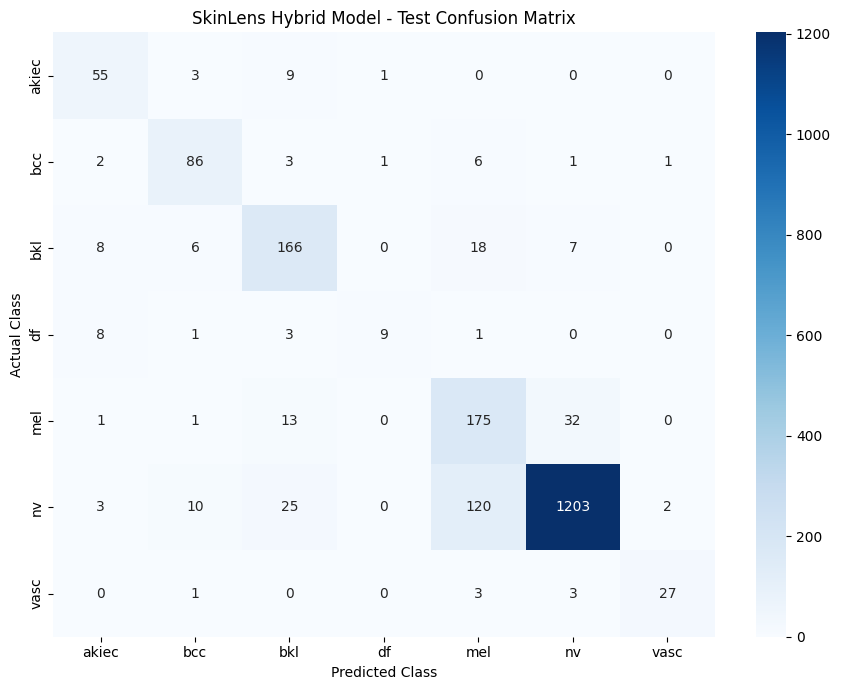

In [23]:

# STEP 2: Final test-set evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate the best checkpoint
test_result = run_validation(model, test_loader)

y_true = test_result["y_true"]
y_pred = test_result["y_pred"]

class_names = [
    "akiec", "bcc", "bkl", "df",
    "mel", "nv", "vasc"
]

print("TEST ACCURACY:",
      round(accuracy_score(y_true, y_pred), 4))

print("TEST MACRO F1:",
      round(f1_score(
          y_true, y_pred,
          average="macro",
          zero_division=0
      ), 4))

print("\nCLASSIFICATION REPORT:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(7))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("SkinLens Hybrid Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [20]:

# Load best validation checkpoint

checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

print("Best hybrid model loaded successfully!")
print("Model: EfficientNetV2-S + Swin Transformer V2")
print("Metadata fusion: Enabled")
print("Classes:", Config.NUM_CLASSES)
print("Device:", device)


Best hybrid model loaded successfully!
Model: EfficientNetV2-S + Swin Transformer V2
Metadata fusion: Enabled
Classes: 7
Device: cuda


,epoch,train_loss,val_macro_f1,val_accuracy
0,1,1.018365,0.655239,0.671515
1,2,0.747120,0.692430,0.720662
2,3,0.686536,0.715078,0.798395
3,4,0.618813,0.732004,0.788365
4,5,0.598049,0.780153,0.850552
5,6,0.586261,0.773968,0.852056
6,7,0.567117,0.778357,0.841525
7,8,0.561408,0.782669,0.841525
8,9,0.549981,0.777925,0.845035
9,10,0.544123,0.775538,0.848044


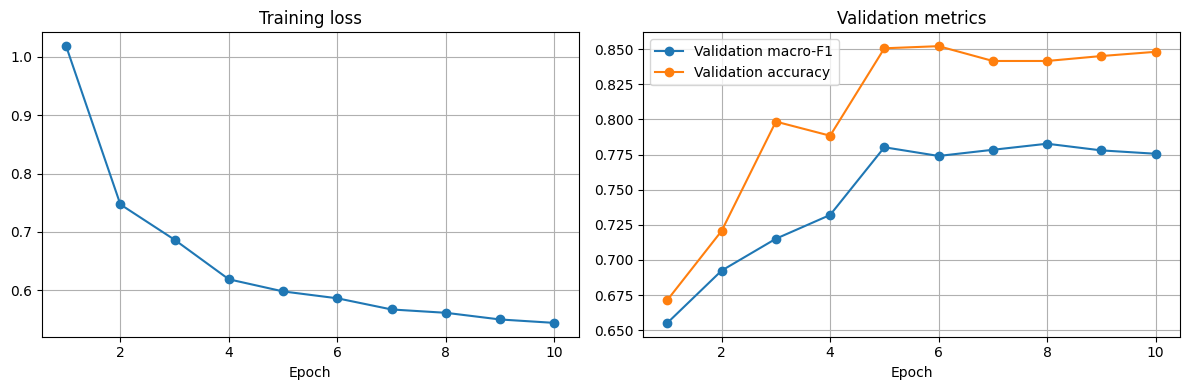

Loaded: skinlens_ham10000_output/best_skinlens_hybrid.pt


In [17]:
# 7. Plot training curves and reload best checkpoint
hist_df = pd.DataFrame(history)
display(hist_df)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o")
ax[0].set_title("Training loss"); ax[0].set_xlabel("Epoch"); ax[0].grid(True)
ax[1].plot(hist_df["epoch"], hist_df["val_macro_f1"], marker="o", label="Validation macro-F1")
ax[1].plot(hist_df["epoch"], hist_df["val_accuracy"], marker="o", label="Validation accuracy")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

if not best_path.exists():
    raise FileNotFoundError("Best checkpoint was not created. Run the training cell successfully first.")
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()
print("Loaded:", best_path)


In [26]:

# ============================================================
# 8. TEMPERATURE SCALING - CORRECTED VERSION
# Fit using VALIDATION data only
# ============================================================

import json
import numpy as np
import torch
import torch.nn.functional as F
from scipy.optimize import minimize_scalar

# ------------------------------------------------------------
# 1. COLLECT VALIDATION LOGITS
# ------------------------------------------------------------

def collect_logits(net, loader):
    net.eval()

    logits_list = []
    labels_list = []

    with torch.no_grad():
        for images, metadata, labels in loader:

            images = images.to(device, non_blocking=True)
            metadata = metadata.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=Config.USE_AMP and device.type == "cuda"
            ):
                logits = net(images, metadata)

            logits_list.append(logits.float().cpu())
            labels_list.append(labels.cpu())

    return torch.cat(logits_list), torch.cat(labels_list)


# ------------------------------------------------------------
# 2. COLLECT VALIDATION PREDICTIONS
# ------------------------------------------------------------

val_logits, val_labels = collect_logits(model, val_loader)

print("Validation logits:", val_logits.shape)
print("Validation labels:", val_labels.shape)


# ------------------------------------------------------------
# 3. OPTIMIZE TEMPERATURE USING VALIDATION NLL
# ------------------------------------------------------------

def temperature_objective(log_temperature):

    temperature = np.exp(log_temperature)

    scaled_logits = val_logits / temperature

    loss = F.cross_entropy(
        scaled_logits,
        val_labels
    )

    return float(loss.item())


# Optimize log-temperature over a wider positive range.
result = minimize_scalar(
    temperature_objective,
    bounds=(np.log(0.05), np.log(100.0)),
    method="bounded",
    options={"xatol": 1e-6}
)

if not result.success:
    raise RuntimeError("Temperature optimization failed: " + result.message)

temperature = float(np.exp(result.x))

print("\nOptimization successful:", result.success)
print("Fitted temperature:", round(temperature, 6))
print("Validation NLL:", round(result.fun, 6))

if temperature > 99.0 or temperature < 0.051:
    print("WARNING: Temperature is close to the search boundary.")
    print("Further calibration investigation may be needed.")


# ------------------------------------------------------------
# 4. SAVE TEMPERATURE AS JSON
# ------------------------------------------------------------

temperature_path = Config.OUTPUT_DIR / "temperature.json"

with open(temperature_path, "w") as f:
    json.dump(
        {"temperature": temperature},
        f,
        indent=4
    )

print("Temperature saved:", temperature_path)


# ------------------------------------------------------------
# 5. EXPECTED CALIBRATION ERROR
# ------------------------------------------------------------

def expected_calibration_error(probs, labels, n_bins=15):

    confidence = probs.max(axis=1)
    predictions = probs.argmax(axis=1)

    correct = (predictions == labels).astype(float)

    bins = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        mask = (
            (confidence >= bins[i]) &
            (
                confidence < bins[i + 1]
                if i < n_bins - 1
                else confidence <= bins[i + 1]
            )
        )

        if mask.any():

            accuracy_bin = correct[mask].mean()
            confidence_bin = confidence[mask].mean()

            ece += mask.mean() * abs(
                accuracy_bin - confidence_bin
            )

    return float(ece)


# ------------------------------------------------------------
# 6. VALIDATION CALIBRATION COMPARISON
# ------------------------------------------------------------

val_probs_raw = torch.softmax(
    val_logits, dim=1
).numpy()

val_probs_cal = torch.softmax(
    val_logits / temperature, dim=1
).numpy()

ece_before = expected_calibration_error(
    val_probs_raw,
    val_labels.numpy()
)

ece_after = expected_calibration_error(
    val_probs_cal,
    val_labels.numpy()
)

print("\n========== VALIDATION CALIBRATION ==========")
print("Temperature:", round(temperature, 6))
print("ECE before:", round(ece_before, 5))
print("ECE after :", round(ece_after, 5))
print("NLL before:", round(
    float(F.cross_entropy(val_logits, val_labels).item()), 5
))
print("NLL after :", round(
    float(F.cross_entropy(
        val_logits / temperature, val_labels
    ).item()), 5
))
print("============================================")


Validation logits: torch.Size([1994, 7])
Validation labels: torch.Size([1994])

Optimization successful: True
Fitted temperature: 1.064053
Validation NLL: 0.744223
Temperature saved: skinlens_ham10000_output/temperature.json

========== VALIDATION CALIBRATION ==========
Temperature: 1.064053
ECE before: 0.15411
ECE after : 0.15409
NLL before: 0.74703
NLL after : 0.74422


Test accuracy: 0.8545
Test macro-F1: 0.7603
Test macro-precision: 0.7849
Test macro-recall: 0.7647
Test ECE raw: 0.1587
Test ECE calibrated: 0.1411

Classification report:
              precision    recall  f1-score   support

       akiec       0.71      0.81      0.76        68
         bcc       0.80      0.86      0.83       100
         bkl       0.76      0.81      0.78       205
          df       0.82      0.41      0.55        22
         mel       0.54      0.79      0.64       222
          nv       0.97      0.88      0.92      1363
        vasc       0.90      0.79      0.84        34

    accuracy                           0.85      2014
   macro avg       0.78      0.76      0.76      2014
weighted avg       0.88      0.85      0.86      2014



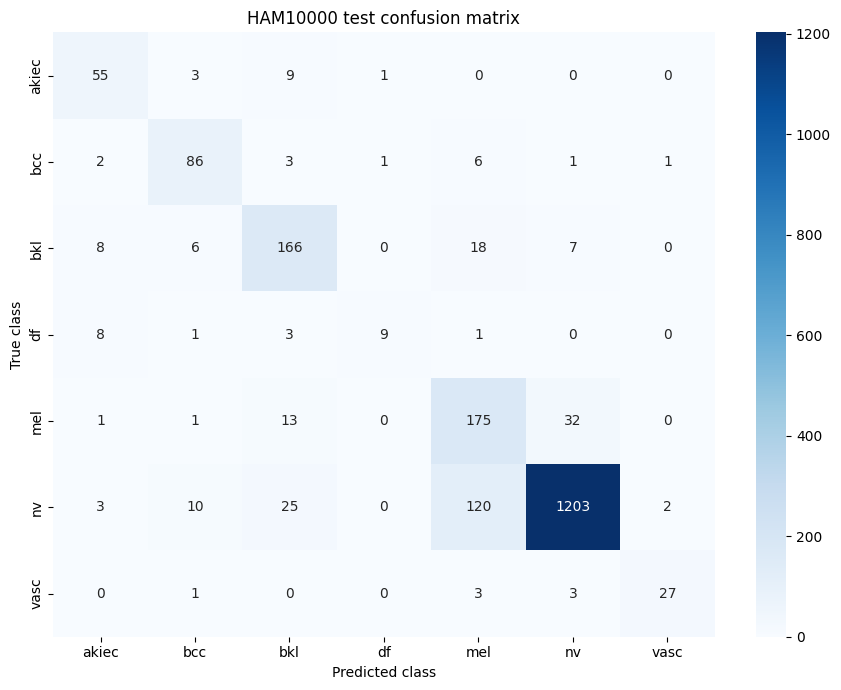

In [19]:
# 9. Final held-out test evaluation — use test set only after choices are fixed
test_logits, test_labels = collect_logits(model, test_loader)
test_probs_raw = torch.softmax(test_logits, dim=1).numpy()
test_probs_cal = torch.softmax(test_logits / temperature, dim=1).numpy()
test_preds = test_probs_cal.argmax(axis=1)
y_true = test_labels.numpy()

print("Test accuracy:", round(accuracy_score(y_true, test_preds), 4))
print("Test macro-F1:", round(f1_score(y_true, test_preds, average="macro", zero_division=0), 4))
print("Test macro-precision:", round(precision_score(y_true, test_preds, average="macro", zero_division=0), 4))
print("Test macro-recall:", round(recall_score(y_true, test_preds, average="macro", zero_division=0), 4))
print("Test ECE raw:", round(expected_calibration_error(test_probs_raw, y_true), 4))
print("Test ECE calibrated:", round(expected_calibration_error(test_probs_cal, y_true), 4))
print("\nClassification report:")
print(classification_report(
    y_true, test_preds, labels=list(range(Config.NUM_CLASSES)),
    target_names=Config.CLASS_NAMES, zero_division=0
))

cm = confusion_matrix(y_true, test_preds, labels=list(range(Config.NUM_CLASSES)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=Config.CLASS_NAMES, yticklabels=Config.CLASS_NAMES)
plt.xlabel("Predicted class"); plt.ylabel("True class")
plt.title("HAM10000 test confusion matrix"); plt.tight_layout(); plt.show()

np.savez(
    Config.OUTPUT_DIR / "test_predictions.npz",
    labels=y_true, logits=test_logits.numpy(), probs_raw=test_probs_raw, probs_calibrated=test_probs_cal
)


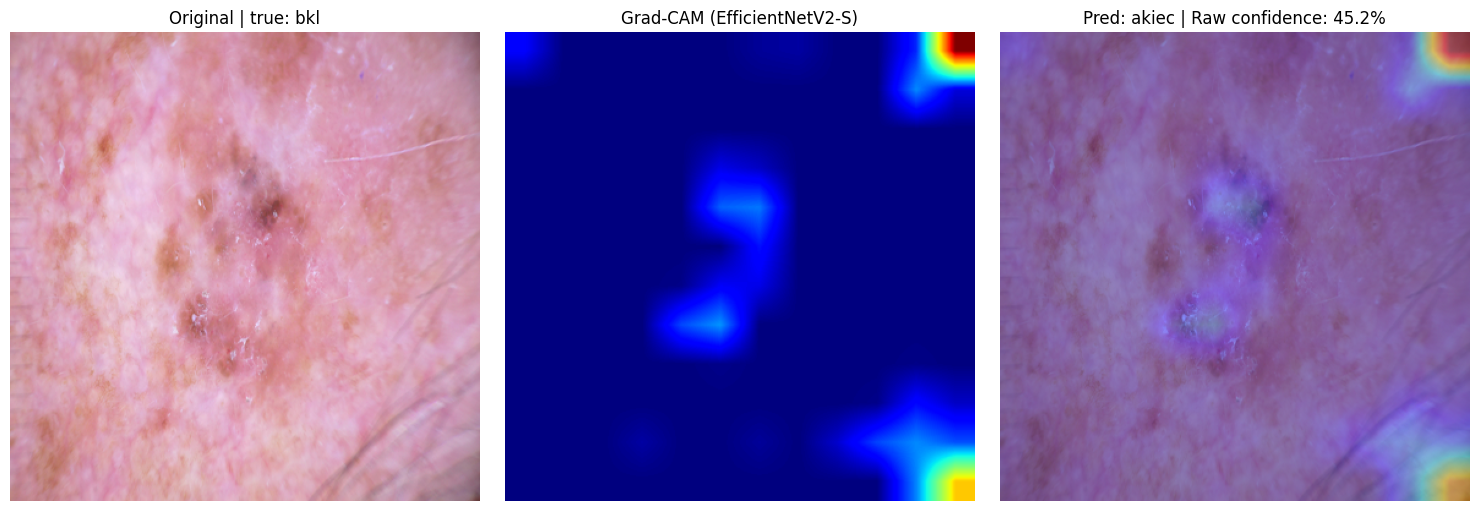

Predicted class: akiec - Actinic keratoses / intraepithelial carcinoma
Raw probability: 0.4521
Note: the Grad-CAM map explains only the EfficientNetV2-S image branch.


In [25]:
# 10. Grad-CAM on the EfficientNetV2-S branch
# This explains the convolutional branch, not the Swin branch or metadata contribution.
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.forward_handle = target_layer.register_forward_hook(self._save_activation)
        self.backward_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inputs, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, image, metadata, target_class=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logits = self.model(image, metadata)
        if target_class is None:
            target_class = int(logits.argmax(1).item())
        logits[0, target_class].backward()

        # Conv feature maps should be [B,C,H,W].
        acts = self.activations[0]
        grads = self.gradients[0]
        weights = grads.mean(dim=(1, 2), keepdim=True)
        cam = torch.relu((weights * acts).sum(dim=0)).detach().cpu().numpy()
        cam = cv2.resize(cam, (Config.IMG_SIZE, Config.IMG_SIZE))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, target_class, torch.softmax(logits.detach(), dim=1)[0].cpu().numpy()

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

# Visualize one test sample.
sample_image, sample_meta, sample_label = test_ds[0]
image_batch = sample_image.unsqueeze(0).to(device)
meta_batch = sample_meta.unsqueeze(0).to(device)
cam_explainer = GradCAM(model, model.effnet.conv_head)
cam, predicted_class, probabilities = cam_explainer.generate(image_batch, meta_batch)
cam_explainer.close()

# Undo ImageNet normalization for display.
img_np = sample_image.permute(1, 2, 0).cpu().numpy()
img_np = (img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])).clip(0, 1)
heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
overlay = (0.6 * img_np + 0.4 * heatmap).clip(0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_np)
axes[0].set_title(f"Original | true: {Config.CLASS_NAMES[int(sample_label)]}")
axes[1].imshow(cam, cmap="jet"); axes[1].set_title("Grad-CAM (EfficientNetV2-S)")
axes[2].imshow(overlay)
axes[2].set_title(
    f"Pred: {Config.CLASS_NAMES[predicted_class]} | "
    f"Raw confidence: {probabilities[predicted_class]:.1%}"
)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

print("Predicted class:", Config.CLASS_NAMES[predicted_class], "-", Config.CLASS_FULL[Config.CLASS_NAMES[predicted_class]])
print("Raw probability:", round(float(probabilities[predicted_class]), 4))
print("Note: the Grad-CAM map explains only the EfficientNetV2-S image branch.")


========== FINAL TEST RESULTS ==========
Test samples: 2014
Temperature: 1.064053
Accuracy: 0.8545
Macro F1: 0.7603
Macro Precision: 0.7849
Macro Recall: 0.7647

Classification Report:

              precision    recall  f1-score   support

       akiec       0.71      0.81      0.76        68
         bcc       0.80      0.86      0.83       100
         bkl       0.76      0.81      0.78       205
          df       0.82      0.41      0.55        22
         mel       0.54      0.79      0.64       222
          nv       0.97      0.88      0.92      1363
        vasc       0.90      0.79      0.84        34

    accuracy                           0.85      2014
   macro avg       0.78      0.76      0.76      2014
weighted avg       0.88      0.85      0.86      2014

Test ECE before calibration: 0.15867
Test ECE after calibration: 0.14118


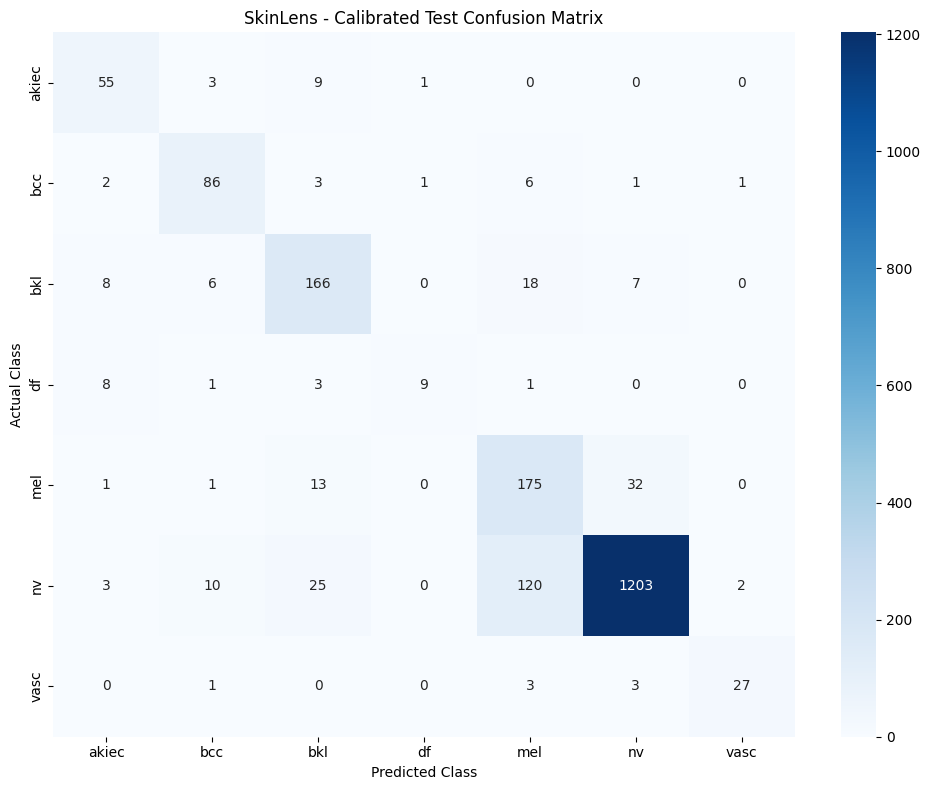


Test evaluation artifacts saved successfully!


In [27]:

# ============================================================
# FINAL SKINLENS TEST EVALUATION
# Uses calibrated probabilities
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import json

# ------------------------------------------------------------
# 1. COLLECT TEST LOGITS
# ------------------------------------------------------------

test_logits, test_labels = collect_logits(model, test_loader)

y_true = test_labels.numpy()

# ------------------------------------------------------------
# 2. LOAD VALIDATION-FITTED TEMPERATURE
# ------------------------------------------------------------

with open(Config.OUTPUT_DIR / "temperature.json", "r") as f:
    temperature = float(json.load(f)["temperature"])

# ------------------------------------------------------------
# 3. CALIBRATE TEST PROBABILITIES
# ------------------------------------------------------------

test_probs_raw = torch.softmax(test_logits, dim=1).numpy()

test_probs_cal = torch.softmax(
    test_logits / temperature,
    dim=1
).numpy()

y_pred = test_probs_cal.argmax(axis=1)

class_names = Config.CLASS_NAMES

# ------------------------------------------------------------
# 4. METRICS
# ------------------------------------------------------------

print("========== FINAL TEST RESULTS ==========")

print("Test samples:", len(y_true))
print("Temperature:", round(temperature, 6))

print("Accuracy:",
      round(accuracy_score(y_true, y_pred), 4))

print("Macro F1:",
      round(f1_score(
          y_true, y_pred,
          average="macro",
          zero_division=0
      ), 4))

print("Macro Precision:",
      round(precision_score(
          y_true, y_pred,
          average="macro",
          zero_division=0
      ), 4))

print("Macro Recall:",
      round(recall_score(
          y_true, y_pred,
          average="macro",
          zero_division=0
      ), 4))

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))

# ------------------------------------------------------------
# 5. TEST ECE
# ------------------------------------------------------------

test_ece_raw = expected_calibration_error(
    test_probs_raw, y_true
)

test_ece_cal = expected_calibration_error(
    test_probs_cal, y_true
)

print("Test ECE before calibration:",
      round(test_ece_raw, 5))

print("Test ECE after calibration:",
      round(test_ece_cal, 5))

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(7))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("SkinLens - Calibrated Test Confusion Matrix")

plt.tight_layout()
plt.savefig(
    Config.OUTPUT_DIR / "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 7. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

np.savez_compressed(
    Config.OUTPUT_DIR / "test_predictions.npz",
    y_true=y_true,
    y_pred=y_pred,
    test_probs_raw=test_probs_raw,
    test_probs_cal=test_probs_cal,
    temperature=temperature
)

print("\nTest evaluation artifacts saved successfully!")


In [28]:

# ============================================================
# SKINLENS - FINAL ARTIFACT EXPORT
# No retraining required
# ============================================================

import os
import json
import shutil
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. CREATE FINAL OUTPUT DIRECTORY
# ------------------------------------------------------------

EXPORT_DIR = Path("/kaggle/working/skinlens_final_artifacts")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Export directory:", EXPORT_DIR)


# ------------------------------------------------------------
# 2. SAVE TRAINED MODEL
# ------------------------------------------------------------

# Save the currently restored model weights
torch.save(
    model.state_dict(),
    EXPORT_DIR / "best_skinlens_hybrid.pt"
)

print("Saved: best_skinlens_hybrid.pt")


# ------------------------------------------------------------
# 3. SAVE TEMPERATURE CALIBRATION
# ------------------------------------------------------------

temperature_data = {
    "temperature": float(temperature),
    "method": "Global temperature scaling",
    "fitted_on": "Validation set only"
}

with open(EXPORT_DIR / "temperature.json", "w") as f:
    json.dump(temperature_data, f, indent=4)

print("Saved: temperature.json")


# ------------------------------------------------------------
# 4. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

np.savez_compressed(
    EXPORT_DIR / "test_predictions.npz",
    y_true=np.asarray(y_true),
    y_pred=np.asarray(y_pred),
    test_probs_raw=np.asarray(test_probs_raw),
    test_probs_cal=np.asarray(test_probs_cal),
    temperature=float(temperature)
)

print("Saved: test_predictions.npz")


# ------------------------------------------------------------
# 5. SAVE CONFUSION MATRIX
# ------------------------------------------------------------

class_names = list(Config.CLASS_NAMES)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("SkinLens - Calibrated Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    EXPORT_DIR / "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Saved: test_confusion_matrix.png")


# ------------------------------------------------------------
# 6. SAVE GRAD-CAM VISUALIZATION
# Uses the already generated Grad-CAM variables
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_np)
axes[0].set_title(
    f"Original | True: {class_names[int(sample_label)]}"
)

axes[1].imshow(cam, cmap="jet")
axes[1].set_title("Grad-CAM (EfficientNetV2-S)")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Pred: {class_names[predicted_class]} | "
    f"Raw confidence: {probabilities[predicted_class]:.1%}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    EXPORT_DIR / "gradcam_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Saved: gradcam_visualization.png")


# ------------------------------------------------------------
# 7. SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

with open(EXPORT_DIR / "classification_report.json", "w") as f:
    json.dump(report, f, indent=4)

print("Saved: classification_report.json")


# ------------------------------------------------------------
# 8. COPY TRAINING HISTORY IF AVAILABLE
# ------------------------------------------------------------

history_candidates = [
    Config.OUTPUT_DIR / "training_history.csv",
    Path("/kaggle/working/skinlens_ham10000_output/training_history.csv")
]

history_found = False

for source in history_candidates:
    if source.exists():
        shutil.copy2(
            source,
            EXPORT_DIR / "training_history.csv"
        )
        history_found = True
        print("Saved: training_history.csv")
        break

if not history_found:
    print("NOTE: Previous training_history.csv not found.")
    print("You can add the CSV from your earlier training session.")


# ------------------------------------------------------------
# 9. SAVE PROJECT CONFIGURATION
# ------------------------------------------------------------

project_info = {
    "project": "SkinLens",
    "dataset": "HAM10000",
    "num_classes": 7,
    "class_names": class_names,
    "architecture": [
        "EfficientNetV2-S",
        "Swin Transformer V2",
        "Metadata Fusion"
    ],
    "image_size": Config.IMG_SIZE,
    "metadata_fusion": True,
    "calibration": "Global temperature scaling",
    "temperature": float(temperature),
    "gradcam_target": "EfficientNetV2-S convolutional branch",
    "test_samples": int(len(y_true)),
    "test_accuracy": float((np.asarray(y_true) == np.asarray(y_pred)).mean())
}

with open(EXPORT_DIR / "project_config.json", "w") as f:
    json.dump(project_info, f, indent=4)

print("Saved: project_config.json")


# ------------------------------------------------------------
# 10. CREATE ZIP PACKAGE
# ------------------------------------------------------------

import zipfile

ZIP_PATH = Path("/kaggle/working/SkinLens_Final_Artifacts.zip")

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for file in EXPORT_DIR.iterdir():
        if file.is_file():
            zipf.write(file, arcname=file.name)


# ------------------------------------------------------------
# 11. VERIFY EXPORTED FILES
# ------------------------------------------------------------

print("\n========== SKINLENS EXPORT COMPLETE ==========")

for file in sorted(EXPORT_DIR.iterdir()):
    if file.is_file():
        print(f"{file.name} | {file.stat().st_size / (1024**2):.2f} MB")

print("\nZIP PACKAGE:", ZIP_PATH)
print("ZIP SIZE:", round(ZIP_PATH.stat().st_size / (1024**2), 2), "MB")


Export directory: /kaggle/working/skinlens_final_artifacts
Saved: best_skinlens_hybrid.pt
Saved: temperature.json
Saved: test_predictions.npz
Saved: test_confusion_matrix.png
Saved: gradcam_visualization.png
Saved: classification_report.json
NOTE: Previous training_history.csv not found.
You can add the CSV from your earlier training session.
Saved: project_config.json

========== SKINLENS EXPORT COMPLETE ==========
best_skinlens_hybrid.pt | 414.08 MB
classification_report.json | 0.00 MB
gradcam_visualization.png | 0.79 MB
project_config.json | 0.00 MB
temperature.json | 0.00 MB
test_confusion_matrix.png | 0.16 MB
test_predictions.npz | 0.10 MB

ZIP PACKAGE: /kaggle/working/SkinLens_Final_Artifacts.zip
ZIP SIZE: 385.52 MB
